# Fraud Detection – Production-Style Prototype
Dataset: `dataset/Fraud_Analysis_Dataset.xlsx` (11,142 transactions, PaySim-style).

**Setup:** `pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm openpyxl` (Python 3.9+). Keep the dataset at `dataset/Fraud_Analysis_Dataset.xlsx` (the notebook also accepts it in the same folder as the notebook). Run all cells from a fresh kernel.

**Prediction moment.** Two use-cases are evaluated and kept separate: **(A) post-transaction detection**, where the final balances (`newbalance*`) are available, and **(B) pre-authorisation detection**, where only information known *before* the transaction is approved may be used. Sections 3-8 are scenario A; section 9 evaluates scenario B explicitly (result: B performs as well as A, see section 9).

**Caveats (read first)**
- The file is a small, **fraud-enriched sample** (~10% fraud vs. far below 1% in full PaySim). Metrics and financial impact are *not* transferable to a real institution.
- `step` leaks the label in this file (all legitimate rows have step 1-7) and is excluded from the model.
- Every fraud row is `TRANSFER` or `CASH_OUT`, so models may just learn the transaction type. Section 9 includes a feature ablation (type-only and amount+type features) to show how much the other features add.
- This is a **production-style prototype**, not production-ready: it needs larger, representative, time-based data and real-world validation.

In [41]:
import warnings; warnings.simplefilter('ignore',FutureWarning); warnings.simplefilter('ignore',DeprecationWarning)   # only known-harmless library warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from IPython.display import display
def show(n): plt.show()
SEED=42; sns.set_theme(style='whitegrid')
from pathlib import Path
# look for the dataset next to the notebook (dataset/ sub-folder or same folder)
DATA=next((p for p in [Path('dataset/Fraud_Analysis_Dataset.xlsx'),Path('Fraud_Analysis_Dataset.xlsx'),Path('../dataset/Fraud_Analysis_Dataset.xlsx')] if p.exists()),None)
assert DATA is not None, 'Place Fraud_Analysis_Dataset.xlsx in a folder named dataset/ next to this notebook (or beside it)'
df=pd.read_excel(DATA); df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


## 1. EDA

In [42]:
print(df.shape); print(df.isna().sum().sum(),'missing |',df.duplicated().sum(),'duplicates')
print(df.isFraud.value_counts().to_dict(), f'fraud rate {df.isFraud.mean():.2%}')
print(df.describe().T)

(11142, 10)
0 missing | 0 duplicates
{0: 10000, 1: 1142} fraud rate 10.25%
                  count          mean           std   min        25%  \
step            11142.0  8.717645e+00  1.606748e+01  1.00     2.0000   
amount          11142.0  2.131915e+05  7.600650e+05  2.39  4946.6175   
oldbalanceOrg   11142.0  9.241173e+05  2.143004e+06  0.00   427.0000   
newbalanceOrig  11142.0  8.249576e+05  2.089894e+06  0.00     0.0000   
oldbalanceDest  11142.0  8.883541e+05  2.601376e+06  0.00     0.0000   
newbalanceDest  11142.0  1.103211e+06  2.982447e+06  0.00     0.0000   
isFraud         11142.0  1.024951e-01  3.033119e-01  0.00     0.0000   

                      50%          75%         max  
step                6.000       7.0000        95.0  
amount          16761.260  154336.5750  10000000.0  
oldbalanceOrg   28169.500  304085.4800  19900000.0  
newbalanceOrig   4420.605  111412.6350  13000000.0  
oldbalanceDest      0.000  271155.4725  33000000.0  
newbalanceDest      0.000  318

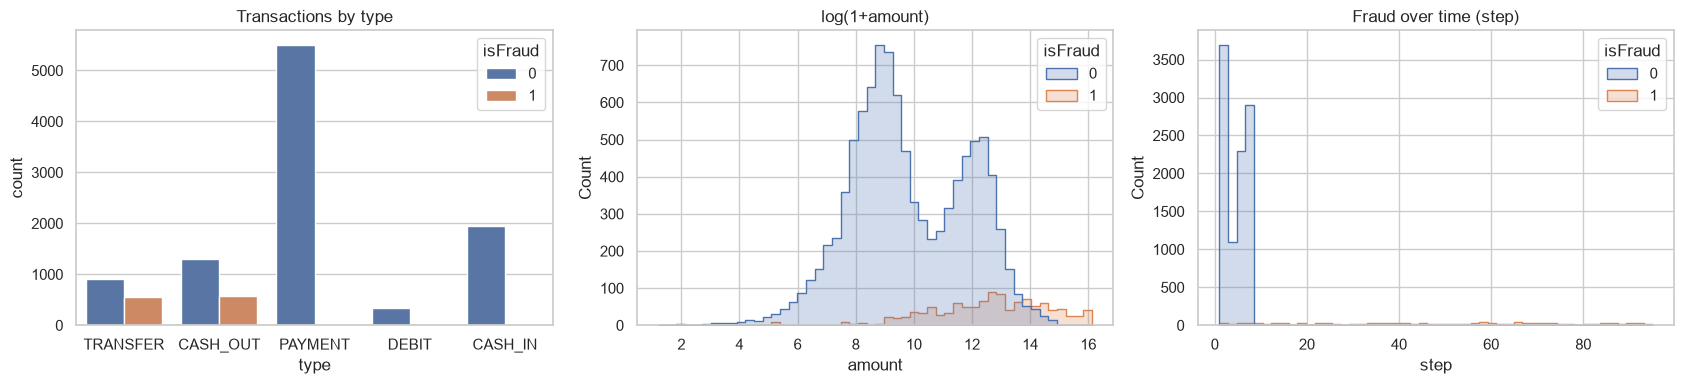

          count  sum      mean
type                          
CASH_IN    1951    0  0.000000
CASH_OUT   1871  578  0.308926
DEBIT       346    0  0.000000
PAYMENT    5510    0  0.000000
TRANSFER   1464  564  0.385246


In [43]:
fig,ax=plt.subplots(1,3,figsize=(17,4))
sns.countplot(data=df,x='type',hue='isFraud',ax=ax[0]); ax[0].set_title('Transactions by type')
sns.histplot(data=df,x=np.log1p(df.amount),hue='isFraud',bins=50,ax=ax[1],element='step'); ax[1].set_title('log(1+amount)')
sns.histplot(data=df,x='step',hue='isFraud',bins=50,ax=ax[2],element='step'); ax[2].set_title('Fraud over time (step)')
plt.tight_layout(); show('fig01')
print(df.groupby('type').isFraud.agg(['count','sum','mean']))

In [44]:
# balance reconciliation: does the ledger add up?
df['errOrig']=df.oldbalanceOrg-df.newbalanceOrig-df.amount
df['errDest']=df.oldbalanceDest+df.amount-df.newbalanceDest
print(df.groupby('isFraud')[['errOrig','errDest']].describe().T)
print('Fraud with origin account fully emptied:',((df.newbalanceOrig==0)&(df.isFraud==1)).sum(),'/',df.isFraud.sum())

isFraud                   0             1
errOrig count  1.000000e+04  1.142000e+03
        mean  -1.261479e+05 -7.937032e+03
        std    2.638134e+05  8.545967e+04
        min   -3.776389e+06 -1.933921e+06
        25%   -1.392886e+05  0.000000e+00
        50%   -5.573715e+03  0.000000e+00
        75%    0.000000e+00  0.000000e+00
        max    1.000000e-02  3.899168e+04
errDest count  1.000000e+04  1.142000e+03
        mean  -6.667089e+04  5.675546e+05
        std    9.852824e+05  1.593695e+06
        min   -1.791996e+07 -8.875516e+06
        25%    1.117910e+03  0.000000e+00
        50%    6.605920e+03  9.439945e+03
        75%    2.993237e+04  3.532465e+05
        max    1.323041e+07  1.000000e+07
Fraud with origin account fully emptied: 1133 / 1142


In [45]:
print(df.groupby('isFraud').step.describe().round(1))
print('Legit max step:',df[df.isFraud==0].step.max(),'| fraud rows with step > that:',(df[df.isFraud==1].step>df[df.isFraud==0].step.max()).sum())

           count  mean   std  min   25%   50%   75%   max
isFraud                                                  
0        10000.0   4.2   2.5  1.0   1.0   5.0   7.0   7.0
1         1142.0  48.3  26.9  1.0  25.0  48.0  70.8  95.0
Legit max step: 7 | fraud rows with step > that: 1064


**Data-quality finding – `step` leaks the label.** Every legitimate transaction has `step` 1–7, while fraud spans 1–95. The file looks like a *concatenation* of a short window of legitimate traffic and fraud sampled from the whole 95-step simulation, so any `step > 7` is fraud by construction. In real data this is impossible, so **`step` is excluded from the model features**. The ablation in section 9 shows how misleadingly good the results get if it is kept.

## 2. Feature engineering & split
`nameOrig`/`nameDest` dropped (high-cardinality IDs), `step` dropped (label leakage, see EDA), `isFraud` is the target only. Added: log amount, balance-change and reconciliation-error features, one-hot `type`. Later (section 4b) extra engineered features are added to fix underfitting of the linear model: log balances and flags such as *account emptied*, *amount equals old balance*, *destination untouched*, *ledger reconciles*, *emptied AND risky type*. The untuned baselines use only the original features (`ORIG`).
Split is **stratified 60/20/20 (train/validation/test)**; the test set is untouched until the final evaluation. Scaling is fit on train only (inside a pipeline for Logistic Regression).

In [46]:
def features(d):
    X=pd.DataFrame({
        'step':d.step,'log_amount':np.log1p(d.amount),
        'oldbalanceOrg':d.oldbalanceOrg,'newbalanceOrig':d.newbalanceOrig,
        'oldbalanceDest':d.oldbalanceDest,'newbalanceDest':d.newbalanceDest,
        'origChange':d.oldbalanceOrg-d.newbalanceOrig,
        'destChange':d.newbalanceDest-d.oldbalanceDest,
        'errOrig':d.oldbalanceOrg-d.newbalanceOrig-d.amount,
        'errDest':d.oldbalanceDest+d.amount-d.newbalanceDest})
    X=pd.concat([X,pd.get_dummies(d.type.astype(pd.CategoricalDtype(['CASH_IN','CASH_OUT','DEBIT','PAYMENT','TRANSFER'])),prefix='type',dtype=int)],axis=1)
    # engineered features: log balances (skew), exact-pattern flags that a linear model cannot build by itself
    for c in ['oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest']: X['log_'+c]=np.log1p(d[c])
    X['orig_emptied']=((d.newbalanceOrig==0)&(d.oldbalanceOrg>0)).astype(int)
    X['amount_eq_oldbal']=(d.amount==d.oldbalanceOrg).astype(int)
    X['dest_zero']=((d.oldbalanceDest==0)&(d.newbalanceDest==0)).astype(int)
    X['orig_recon_ok']=(X.errOrig.abs()<1).astype(int); X['dest_recon_ok']=(X.errDest.abs()<1).astype(int)
    X['risky_type']=X.type_TRANSFER|X.type_CASH_OUT
    X['emptied_risky']=X.orig_emptied*X.risky_type
    return X
X=features(df); y=df.isFraud; amt=df.amount
ENG=[c for c in X.columns if c.startswith('log_old') or c.startswith('log_new') or c in ['orig_emptied','amount_eq_oldbal','dest_zero','orig_recon_ok','dest_recon_ok','risky_type','emptied_risky']]
ORIG=[c for c in X.columns if c not in ENG and c!='step']   # original feature set (used for the untuned baselines)
Xstep=X['step']; X=X.drop(columns='step')   # step leaks the label in this sample (see EDA); kept only for the ablation
Xtr,Xtmp,ytr,ytmp=train_test_split(X,y,test_size=.4,stratify=y,random_state=SEED)
Xva,Xte,yva,yte=train_test_split(Xtmp,ytmp,test_size=.5,stratify=ytmp,random_state=SEED)
print(Xtr.shape,Xva.shape,Xte.shape)

(6685, 25) (2228, 25) (2229, 25)


### Findings – EDA

In [47]:
from IPython.display import Markdown
display(Markdown(f'''- **Size / balance:** {len(df):,} transactions, {df.isFraud.sum():,} fraud ({df.isFraud.mean():.2%}). No missing values or duplicates.
- **Type:** fraud occurs only in TRANSFER ({int(((df.type=='TRANSFER')&(df.isFraud==1)).sum())}) and CASH_OUT ({int(((df.type=='CASH_OUT')&(df.isFraud==1)).sum())}). Fraud rates: TRANSFER {df[df.type=='TRANSFER'].isFraud.mean():.1%}, CASH_OUT {df[df.type=='CASH_OUT'].isFraud.mean():.1%}; PAYMENT, CASH_IN, DEBIT 0%.
- **Amount:** median fraud amount {df[df.isFraud==1].amount.median():,.0f} vs {df[df.isFraud==0].amount.median():,.0f} for legitimate transactions ({df[df.isFraud==1].amount.median()/df[df.isFraud==0].amount.median():.0f}x). Amounts are heavily right-skewed, hence the log transform.
- **Account emptying:** {int(((df.newbalanceOrig==0)&(df.isFraud==1)).sum())} of {df.isFraud.sum()} frauds drain the sender's account to exactly 0, a classic account-takeover signature.
- **Ledger reconciliation:** median `errOrig` is {df[df.isFraud==1].errOrig.median():,.0f} for fraud (sender balance falls exactly by the amount) versus {df[df.isFraud==0].errOrig.median():,.0f} for legitimate; the destination ledger (`errDest`) often fails to reconcile for fraud, as the money is not credited as expected.
- **Caution:** this is a fraud-enriched, curated sample; fraud rate is ~10x the real PaySim rate.'''))

- **Size / balance:** 11,142 transactions, 1,142 fraud (10.25%). No missing values or duplicates.
- **Type:** fraud occurs only in TRANSFER (564) and CASH_OUT (578). Fraud rates: TRANSFER 38.5%, CASH_OUT 30.9%; PAYMENT, CASH_IN, DEBIT 0%.
- **Amount:** median fraud amount 353,179 vs 12,725 for legitimate transactions (28x). Amounts are heavily right-skewed, hence the log transform.
- **Account emptying:** 1133 of 1142 frauds drain the sender's account to exactly 0, a classic account-takeover signature.
- **Ledger reconciliation:** median `errOrig` is 0 for fraud (sender balance falls exactly by the amount) versus -5,574 for legitimate; the destination ledger (`errDest`) often fails to reconcile for fraud, as the money is not credited as expected.
- **Caution:** this is a fraud-enriched, curated sample; fraud rate is ~10x the real PaySim rate.

## 3. Baseline: Logistic Regression

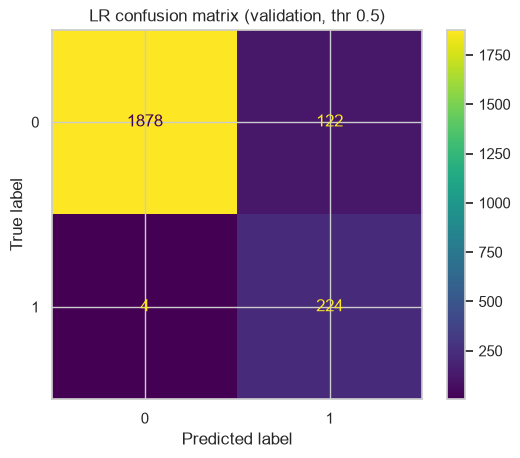

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.943447,0.647399,0.982456,0.780488,0.992857,0.969912


In [48]:
def report(name,y_true,p,thr=.5):
    pred=(p>=thr).astype(int)
    return dict(model=name,accuracy=accuracy_score(y_true,pred),precision=precision_score(y_true,pred,zero_division=0),recall=recall_score(y_true,pred),
        f1=f1_score(y_true,pred),roc_auc=roc_auc_score(y_true,p),pr_auc=average_precision_score(y_true,p))
res=[]
lr=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED)).fit(Xtr[ORIG],ytr)
res.append(report('Logistic Regression',yva,lr.predict_proba(Xva[ORIG])[:,1]))
ConfusionMatrixDisplay(confusion_matrix(yva,lr.predict(Xva[ORIG]))).plot(); plt.title('LR confusion matrix (validation, thr 0.5)'); show('fig02')
pd.DataFrame(res)

### Findings – baselines

In [49]:
from IPython.display import Markdown
display(Markdown(f'''- **Logistic Regression (original features, untuned)**: precision {res[0]['precision']:.1%}, recall {res[0]['recall']:.1%}, PR-AUC {res[0]['pr_auc']:.3f}. A linear model is a reasonable baseline but still produces false alarms and misses some frauds because the signals are non-linear (e.g. balance equals amount AND new balance is 0).'''))

- **Logistic Regression (original features, untuned)**: precision 64.7%, recall 98.2%, PR-AUC 0.970. A linear model is a reasonable baseline but still produces false alarms and misses some frauds because the signals are non-linear (e.g. balance equals amount AND new balance is 0).

## 4. Untuned baseline models (original features, validation set, threshold 0.5)

In [50]:
pos=(ytr==0).sum()/(ytr==1).sum()
models={'Random Forest':RandomForestClassifier(400,class_weight='balanced',n_jobs=-1,random_state=SEED),
 'XGBoost':XGBClassifier(n_estimators=300,max_depth=5,learning_rate=.1,scale_pos_weight=pos,eval_metric='aucpr',random_state=SEED),
 'LightGBM':LGBMClassifier(n_estimators=300,learning_rate=.1,scale_pos_weight=pos,random_state=SEED,verbose=-1)}
for n,m in models.items():
    m.fit(Xtr[ORIG],ytr); res.append(report(n,yva,m.predict_proba(Xva[ORIG])[:,1]))
models['Logistic Regression']=lr
base_models=dict(models)   # kept for the before/after overfitting comparison
cmp0=pd.DataFrame(res).set_index('model').round(4); display(cmp0)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Logistic Regression,0.9434,0.6474,0.9825,0.7805,0.9929,0.9699
Random Forest,0.9973,0.9912,0.9825,0.9868,0.9967,0.9924
XGBoost,0.9982,0.9956,0.9868,0.9912,0.9989,0.9954
LightGBM,0.9978,0.9956,0.9825,0.9890,0.9967,0.9936


## 4b. Fixing over/underfitting: regularisation, tuning and better features
The diagnosis in section 12 (before) shows two problems; these are the measures taken:
- **Overfitting of tree models** (train F1 1.0 vs validation lower): limit tree depth/leaves, require more samples per leaf, subsample rows/columns, add L2 regularisation, and pick hyper-parameters by **3-fold cross-validation on the training set only** (scoring PR-AUC) via randomised search. Validation and test sets are not used for tuning.
- **Underfitting of Logistic Regression** (low score on every set): add the engineered non-linear features listed in section 2 (log balances, emptied-account, amount==old balance, ledger-reconciles, emptied AND risky type) and tune the regularisation strength `C`.

In [51]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
cv3=StratifiedKFold(3,shuffle=True,random_state=SEED)
SPACES={
 'Random Forest':(RandomForestClassifier(class_weight='balanced',n_jobs=-1,random_state=SEED),
   {'n_estimators':[200,400],'max_depth':[4,6,8,12],'min_samples_leaf':[2,5,10,20],'max_features':['sqrt',.5]}),
 'XGBoost':(XGBClassifier(scale_pos_weight=pos,eval_metric='aucpr',random_state=SEED,n_jobs=1),
   {'n_estimators':[150,300,500],'max_depth':[2,3,4,5],'learning_rate':[.03,.05,.1],'subsample':[.7,.85,1],'colsample_bytree':[.6,.8,1],'min_child_weight':[1,3,5],'reg_lambda':[1,5,10]}),
 'LightGBM':(LGBMClassifier(scale_pos_weight=pos,random_state=SEED,verbose=-1,n_jobs=1,subsample_freq=1),
   {'n_estimators':[150,300,500],'num_leaves':[7,15,31],'max_depth':[-1,4,6],'learning_rate':[.03,.05,.1],'subsample':[.7,.85,1],'colsample_bytree':[.6,.8,1],'min_child_samples':[10,20,40],'reg_lambda':[1,5,10]})}
def searcher(n,n_iter=15):
    if n=='Logistic Regression':
        return GridSearchCV(make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000,class_weight='balanced',random_state=SEED)),
                            {'logisticregression__C':[.01,.1,1,10,100]},cv=cv3,scoring='average_precision',n_jobs=-1)
    est,space=SPACES[n]; return RandomizedSearchCV(est,space,n_iter=n_iter,cv=cv3,scoring='average_precision',random_state=SEED,n_jobs=-1)
tuned={}; best_params={}
for n in ['Logistic Regression','Random Forest','XGBoost','LightGBM']:
    s=searcher(n).fit(Xtr,ytr); tuned[n]=s.best_estimator_; best_params[n]=s.best_params_; print(n,s.best_params_)
models=tuned
res2=[report(n,yva,m.predict_proba(Xva)[:,1]) for n,m in tuned.items()]
cmp=pd.DataFrame(res2).set_index('model').round(4); display(cmp)
best=cmp.pr_auc.idxmax(); print('Best by validation PR-AUC:',best)

Logistic Regression {'logisticregression__C': 10}
Random Forest {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 8}
XGBoost {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
LightGBM {'subsample': 1, 'reg_lambda': 5, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Logistic Regression,0.9960,0.9782,0.9825,0.9803,0.9986,0.9938
Random Forest,0.9982,1.0000,0.9825,0.9912,0.9991,0.9956
XGBoost,0.9982,1.0000,0.9825,0.9912,0.9993,0.9962
LightGBM,0.9982,1.0000,0.9825,0.9912,0.9990,0.9953


Best by validation PR-AUC: XGBoost


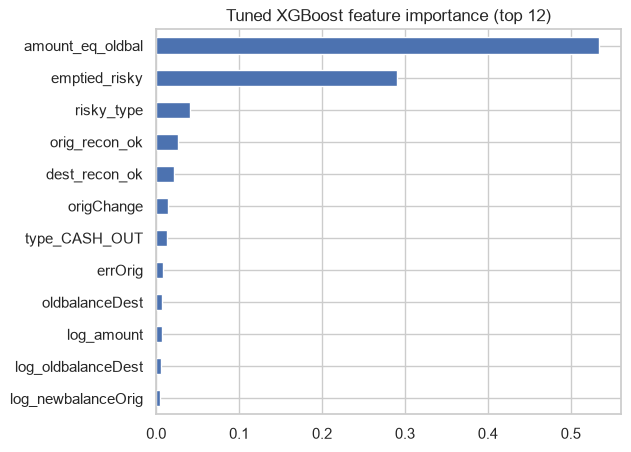

In [52]:
imp=pd.Series(models['XGBoost'].feature_importances_,X.columns).sort_values()
imp.tail(12).plot.barh(figsize=(6,5),title='Tuned XGBoost feature importance (top 12)'); show('fig03')

### Findings – model comparison

In [53]:
from IPython.display import Markdown
display(Markdown(f'''- Best tuned model by validation PR-AUC: **{best}** (PR-AUC {cmp.loc[best,'pr_auc']:.4f}, F1 {cmp.loc[best,'f1']:.4f}).
- Logistic Regression improved from F1 {cmp0.loc['Logistic Regression','f1']:.3f} (original features) to {cmp.loc['Logistic Regression','f1']:.3f} (engineered features, tuned C); it is still compared against the tree ensembles (best F1 {cmp.drop(['Logistic Regression']).f1.max():.3f}).
- Differences between Random Forest, XGBoost and LightGBM are tiny and within noise on this small set; see cross-validation (section 8). The ranking of the three is therefore not conclusive.
- Top XGBoost features: {', '.join(imp.sort_values(ascending=False).index[:4])}. Importance ranks which inputs the trees split on, not causal proof.'''))

- Best tuned model by validation PR-AUC: **XGBoost** (PR-AUC 0.9962, F1 0.9912).
- Logistic Regression improved from F1 0.780 (original features) to 0.980 (engineered features, tuned C); it is still compared against the tree ensembles (best F1 0.991).
- Differences between Random Forest, XGBoost and LightGBM are tiny and within noise on this small set; see cross-validation (section 8). The ranking of the three is therefore not conclusive.
- Top XGBoost features: amount_eq_oldbal, emptied_risky, risky_type, orig_recon_ok. Importance ranks which inputs the trees split on, not causal proof.

## 5. Threshold optimisation
**Assumptions (change freely):** a missed fraud loses the full transaction amount; each alert (true or false) costs `INVESTIGATION_COST` to review; a blocked legitimate transaction forfeits its fee `FEE`; a caught fraud recovers its amount. Two operating points are chosen on **validation** and then frozen for the test set: (a) the **max-F1** threshold (balanced precision/recall, used as the headline) and (b) the **minimum-cost** threshold (very aggressive, because missed frauds are huge).

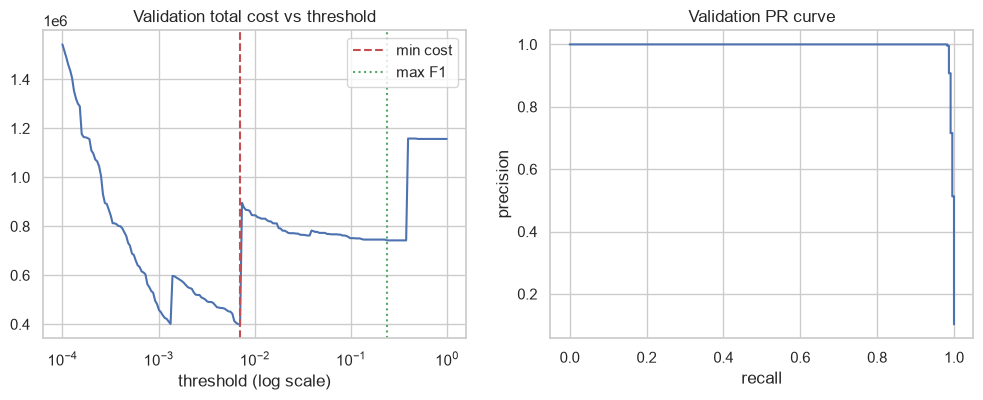

Max-F1 threshold (headline): 0.236 | cost-optimal threshold: 0.0070


In [54]:
INVESTIGATION_COST=25.0   # assumption: currency units per alert reviewed (the dataset does not state a currency)
FEE=0.01                 # assumption: commission earned on each approved legitimate transaction
def cost(y_true,p,a,thr):
    pred=p>=thr; fn=~pred&(y_true==1); fp=pred&(y_true==0)
    lost_fee=FEE*a[fp].sum()   # fee forfeited on blocked legitimate transactions
    return dict(missed_loss=a[fn].sum(),review_cost=pred.sum()*INVESTIGATION_COST,lost_fee=lost_fee,total=a[fn].sum()+pred.sum()*INVESTIGATION_COST+lost_fee)
pva=models[best].predict_proba(Xva)[:,1]; ava=amt.loc[yva.index]
grid=np.logspace(-4,np.log10(.99),200)   # fine grid down to 0.0001: missed frauds are very expensive
tot=[cost(yva,pva,ava,t)['total'] for t in grid]
thr_cost=grid[int(np.argmin(tot))]   # cost-optimal: very aggressive because misses are huge
f1s=[f1_score(yva,pva>=g) for g in grid]; thr=grid[int(np.argmax(f1s))]   # headline: max-F1 on validation (stable, balanced)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].semilogx(grid,tot); ax[0].axvline(thr_cost,c='r',ls='--',label='min cost'); ax[0].axvline(thr,c='g',ls=':',label='max F1'); ax[0].legend(); ax[0].set(title='Validation total cost vs threshold',xlabel='threshold (log scale)')
pr,rc,_=precision_recall_curve(yva,pva); ax[1].plot(rc,pr); ax[1].set(title='Validation PR curve',xlabel='recall',ylabel='precision')
show('fig04'); print(f'Max-F1 threshold (headline): {thr:.3f} | cost-optimal threshold: {thr_cost:.4f}')

### Findings – threshold choice

In [55]:
from IPython.display import Markdown
display(Markdown(f'''- **Headline (max-F1) threshold: {thr:.3f}**; **cost-optimal threshold: {thr_cost:.4f}** (validation cost {min(tot):,.0f} vs {tot[int(np.argmin(np.abs(grid-.5)))]:,.0f} at 0.5).
- A missed fraud costs its full (very large) amount, a false alarm only a review, so the cost-optimal threshold is pushed close to 0 and flags many legitimate transactions. It is driven by a handful of huge frauds and therefore fragile; the max-F1 point is the safer default. Both are evaluated on the test set below.'''))

- **Headline (max-F1) threshold: 0.236**; **cost-optimal threshold: 0.0070** (validation cost 399,138 vs 1,156,654 at 0.5).
- A missed fraud costs its full (very large) amount, a false alarm only a review, so the cost-optimal threshold is pushed close to 0 and flags many legitimate transactions. It is driven by a handful of huge frauds and therefore fragile; the max-F1 point is the safer default. Both are evaluated on the test set below.

## 6. Final evaluation on untouched test set

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
XGBoost @thr 0.236,0.9978,0.9956,0.9825,0.9890,0.9989,0.9950
Logistic Regression @0.5,0.9969,0.9868,0.9825,0.9847,0.9968,0.9903


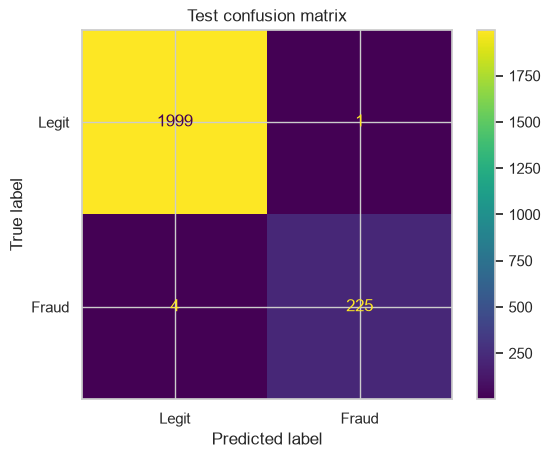

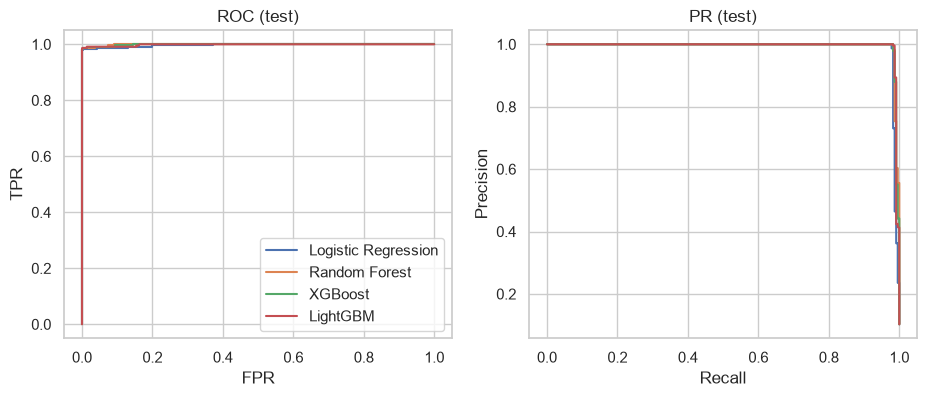

Fraud value in test set (no model): 269,568,762
With model: missed loss 4,497,357 + review cost 5,650 = 4,504,076
Net saving vs no model: 265,064,686


In [56]:
pte=models[best].predict_proba(Xte)[:,1]; ate=amt.loc[yte.index]
final=pd.DataFrame([report(best+f' @thr {thr:.3f}',yte,pte,thr),
                    report('Logistic Regression @0.5',yte,models['Logistic Regression'].predict_proba(Xte)[:,1])]).set_index('model').round(4)
display(final)
ConfusionMatrixDisplay(confusion_matrix(yte,pte>=thr),display_labels=['Legit','Fraud']).plot(); plt.title('Test confusion matrix'); show('fig05')
fig,ax=plt.subplots(1,2,figsize=(11,4))
for n,m in models.items():
    p=m.predict_proba(Xte)[:,1]; f,t,_=roc_curve(yte,p); ax[0].plot(f,t,label=n)
    pr,rc,_=precision_recall_curve(yte,p); ax[1].plot(rc,pr,label=n)
ax[0].set(title='ROC (test)',xlabel='FPR',ylabel='TPR'); ax[1].set(title='PR (test)',xlabel='Recall',ylabel='Precision'); ax[0].legend(); show('fig06')
c=cost(yte,pte,ate,thr); nofilter=ate[yte==1].sum()
print(f"Fraud value in test set (no model): {nofilter:,.0f}")
print(f"With model: missed loss {c['missed_loss']:,.0f} + review cost {c['review_cost']:,.0f} = {c['total']:,.0f}")
print(f"Net saving vs no model: {nofilter-c['total']:,.0f}")

### Findings – final test performance

In [57]:
from IPython.display import Markdown
display(Markdown(f'''- On {len(yte):,} untouched transactions at threshold {thr:.3f}: precision **{precision_score(yte,pte>=thr):.2%}**, recall **{recall_score(yte,pte>=thr):.2%}**, F1 {f1_score(yte,pte>=thr):.3f}, ROC-AUC {roc_auc_score(yte,pte):.4f}, PR-AUC {average_precision_score(yte,pte):.4f}.
- Confusion matrix: TN={confusion_matrix(yte,pte>=thr)[0,0]}, FP={confusion_matrix(yte,pte>=thr)[0,1]}, FN={confusion_matrix(yte,pte>=thr)[1,0]}, TP={confusion_matrix(yte,pte>=thr)[1,1]}.
- The tuned Logistic Regression is close to the tree models (see the table above).
- The test set holds only {int(yte.sum())} frauds, so each missed fraud moves recall by {1/yte.sum():.2%}.'''))

- On 2,229 untouched transactions at threshold 0.236: precision **99.56%**, recall **98.25%**, F1 0.989, ROC-AUC 0.9989, PR-AUC 0.9950.
- Confusion matrix: TN=1999, FP=1, FN=4, TP=225.
- The tuned Logistic Regression is close to the tree models (see the table above).
- The test set holds only 229 frauds, so each missed fraud moves recall by 0.44%.

## 7. Financial impact analysis
**Explicit assumptions (edit the cell below):** the company earns a `FEE` commission on every legitimate transaction it approves; a missed fraud loses the full transaction amount; every flagged transaction costs `INVESTIGATION_COST` to review; a flagged legitimate transaction (false positive) is blocked/delayed so its fee is lost. All figures are **test-set estimates** (20% of the data, not scaled to a year), in unspecified currency units, and illustrative only. Recovery of stolen funds is assumed to be zero for missed fraud. Fee revenue is counted only on legitimate transactions that are approved (true negatives), so the fee lost on false positives is already excluded from `revenue`; subtracting it again would double count. The assertion below checks this identity.

,revenue,fraud_loss,review_cost,lost_fee_FP,profit,TP,FP,FN,TN,fraud_prevented
scenario,,,,,,,,,,
No model (approve all),2130736.0,269568762.0,0.0,0.0,-267438025.0,0,0,229,2000,0.0
Logistic Regression,2126552.0,4497357.0,5700.0,4185.0,-2376505.0,225,3,4,1997,265071405.0
XGBoost (tuned),2129667.0,4497357.0,5650.0,1069.0,-2373339.0,225,1,4,1999,265071405.0
XGBoost (cost-optimal thr),1945637.0,3329771.0,8000.0,185100.0,-1392135.0,227,93,2,1907,266238991.0


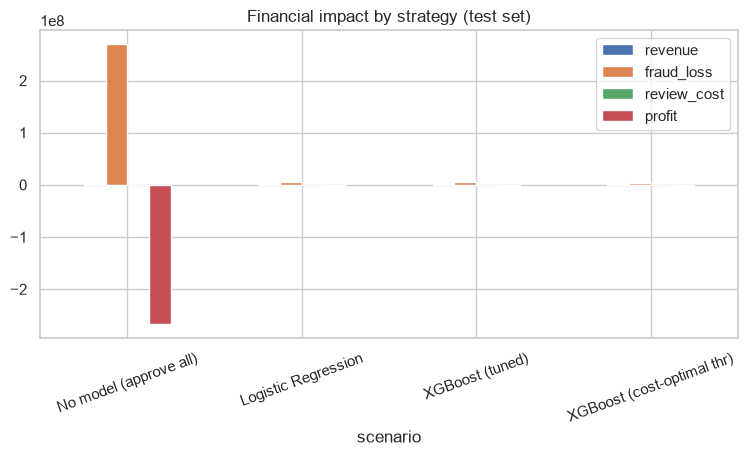

In [58]:
def scenario(name,flag):
    flag=np.asarray(flag).astype(bool); yt=yte.values; a=ate.values
    tp=flag&(yt==1); fp=flag&(yt==0); fn=~flag&(yt==1); tn=~flag&(yt==0)
    revenue=FEE*a[tn].sum(); fraud_loss=a[fn].sum(); review=flag.sum()*INVESTIGATION_COST; lost_fee=FEE*a[fp].sum()
    return dict(scenario=name,revenue=revenue,fraud_loss=fraud_loss,review_cost=review,lost_fee_FP=lost_fee,
                profit=revenue-fraud_loss-review,   # revenue already excludes fees of blocked (FP) transactions
                check=FEE*a[yt==0].sum()-lost_fee-fraud_loss-review,TP=int(tp.sum()),FP=int(fp.sum()),FN=int(fn.sum()),TN=int(tn.sum()),fraud_prevented=a[tp].sum())
fin=pd.DataFrame([scenario('No model (approve all)',np.zeros(len(yte))),
                  scenario('Logistic Regression',models['Logistic Regression'].predict_proba(Xte)[:,1]>=.5),
                  scenario(f'{best} (tuned)',pte>=thr),
                  scenario(f'{best} (cost-optimal thr)',pte>=thr_cost)]).set_index('scenario')
assert (abs(fin.profit-fin.check)<1e-6).all(), 'profit = fee on all legit - lost FP fee - fraud loss - review'
fin=fin.drop(columns='check')
display(fin.round(0).astype({c:'int64' for c in ['TP','FP','FN','TN']}))
fin[['revenue','fraud_loss','review_cost','profit']].plot.bar(figsize=(9,4),title='Financial impact by strategy (test set)'); plt.xticks(rotation=20); show('fin')

In [59]:
# Sensitivity of profit uplift to the assumed review cost and fee
rows=[]
for ic in [5,25,100,500]:
    for fee in [.005,.01,.02]:
        INVESTIGATION_COST=ic; FEE=fee
        base=scenario('b',np.zeros(len(yte)))['profit']; m=scenario('m',pte>=thr)['profit']
        rows.append(dict(review_cost=ic,fee=fee,profit_uplift=m-base))
INVESTIGATION_COST=25.0; FEE=.01
sens=pd.DataFrame(rows)
print('Model profit minus no-model profit (test-set estimate)'); display(sens.pivot(index='review_cost',columns='fee',values='profit_uplift').round(0))

Model profit minus no-model profit (test-set estimate)


fee,0.005,0.010,0.020
review_cost,,,
5,265069741.0,265069206.0,265068137.0
25,265065221.0,265064686.0,265063617.0
100,265048271.0,265047736.0,265046667.0
500,264957871.0,264957336.0,264956267.0


### Findings – financial impact

In [60]:
from IPython.display import Markdown
display(Markdown(f'''- **No model:** fraud losses of {fin.iloc[0].fraud_loss:,.0f} against revenue of {fin.iloc[0].revenue:,.0f}, profit {fin.iloc[0].profit:,.0f}.
- **Logistic Regression:** profit {fin.iloc[1].profit:,.0f}; {int(fin.iloc[1].FN)} missed frauds cost {fin.iloc[1].fraud_loss:,.0f}.
- **{best} (max-F1 threshold):** profit {fin.iloc[2].profit:,.0f}; {int(fin.iloc[2].FN)} missed frauds ({fin.iloc[2].fraud_loss:,.0f}), {int(fin.iloc[2].FP)} false alarms. Uplift over no model: {fin.iloc[2].profit-fin.iloc[0].profit:,.0f}.
- **{best} (cost-optimal threshold):** profit {fin.iloc[3].profit:,.0f}, {int(fin.iloc[3].FN)} missed frauds, {int(fin.iloc[3].FP)} false alarms.
- **Best ML strategy by profit on test: {fin.profit.iloc[1:].idxmax()}.** When a single missed fraud can cost more than all review costs combined, a handful of misses decides the profit ranking, so a lower threshold (more alerts, fewer misses) can be more profitable than the max-F1 threshold even though precision falls. Choose the operating point according to the real cost of a missed fraud versus a review.
- **Caveat:** the uplift over approving everything ({fin.iloc[2].profit-fin.iloc[0].profit:,.0f}) is a test-set estimate under assumed costs and zero recovery of stolen funds, in unspecified currency units. It is not actual or annual company savings, and it is inflated because the sample is fraud-enriched and every fraud is large.
- **Sensitivity:** the uplift stays huge for any review cost (5-500) and fee (0.5-2%) because fraud amounts dominate; versus no model the conclusion is robust to the assumptions (the fee does not change that uplift because the model produces no false positives, so the same legitimate fees are earned either way). Absolute figures are illustrative.
- Fraud losses are inflated by the curated sample (every fraud is large and 10% of rows). Real losses would be far lower in absolute terms.'''))

- **No model:** fraud losses of 269,568,762 against revenue of 2,130,736, profit -267,438,025.
- **Logistic Regression:** profit -2,376,505; 4 missed frauds cost 4,497,357.
- **XGBoost (max-F1 threshold):** profit -2,373,339; 4 missed frauds (4,497,357), 1 false alarms. Uplift over no model: 265,064,686.
- **XGBoost (cost-optimal threshold):** profit -1,392,135, 2 missed frauds, 93 false alarms.
- **Best ML strategy by profit on test: XGBoost (cost-optimal thr).** When a single missed fraud can cost more than all review costs combined, a handful of misses decides the profit ranking, so a lower threshold (more alerts, fewer misses) can be more profitable than the max-F1 threshold even though precision falls. Choose the operating point according to the real cost of a missed fraud versus a review.
- **Caveat:** the uplift over approving everything (265,064,686) is a test-set estimate under assumed costs and zero recovery of stolen funds, in unspecified currency units. It is not actual or annual company savings, and it is inflated because the sample is fraud-enriched and every fraud is large.
- **Sensitivity:** the uplift stays huge for any review cost (5-500) and fee (0.5-2%) because fraud amounts dominate; versus no model the conclusion is robust to the assumptions (the fee does not change that uplift because the model produces no false positives, so the same legitimate fees are earned either way). Absolute figures are illustrative.
- Fraud losses are inflated by the curated sample (every fraud is large and 10% of rows). Real losses would be far lower in absolute terms.

## 8. Robustness: nested 5-fold cross-validation (train+validation)
Hyper-parameters are chosen by an *inner* 3-fold search inside every *outer* training fold, so the outer-fold scores are not contaminated by the tuning (nested CV). The search is smaller (6 draws) than in section 4b to keep run-time reasonable. The test set is not used.

In [61]:
from sklearn.model_selection import cross_validate
Xdev=pd.concat([Xtr,Xva]); ydev=pd.concat([ytr,yva]); cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
cvres={}
for n in models:
    r=cross_validate(searcher(n,n_iter=6),Xdev,ydev,cv=cv,scoring={'pr':'average_precision','f1':'f1'},n_jobs=1)
    cvres[n]=dict(pr_auc_mean=r['test_pr'].mean(),pr_auc_std=r['test_pr'].std(),f1_mean=r['test_f1'].mean(),f1_std=r['test_f1'].std())
cvdf=pd.DataFrame(cvres).T.round(4); display(cvdf)

,pr_auc_mean,pr_auc_std,f1_mean,f1_std
Logistic Regression,0.9949,0.0043,0.9874,0.0044
Random Forest,0.9945,0.0030,0.9889,0.0039
XGBoost,0.9946,0.0035,0.9890,0.0046
LightGBM,0.9950,0.0028,0.9895,0.0041


### Findings – cross-validation

In [62]:
from IPython.display import Markdown
display(Markdown(f'''- Nested 5-fold PR-AUC for {best}: {cvdf.loc[best,'pr_auc_mean']:.4f} ± {cvdf.loc[best,'pr_auc_std']:.4f}; Logistic Regression: {cvdf.loc['Logistic Regression','pr_auc_mean']:.4f} ± {cvdf.loc['Logistic Regression','pr_auc_std']:.4f}.
- Small standard deviations show scores are stable across folds, not a lucky split; the tuned models are close to each other. This does *not* address time drift or the curated-sample bias.'''))

- Nested 5-fold PR-AUC for XGBoost: 0.9946 ± 0.0035; Logistic Regression: 0.9949 ± 0.0043.
- Small standard deviations show scores are stable across folds, not a lucky split; the tuned models are close to each other. This does *not* address time drift or the curated-sample bias.

## 9. What drives performance? Feature-group ablation and the pre-authorisation scenario
Features are grouped by the information they depend on:
- **Post-transaction balance group** – everything computed from `newbalanceOrig` / `newbalanceDest`: the raw new balances, their logs, balance changes, reconciliation errors/flags, `orig_emptied`, `dest_zero`, `emptied_risky`. These are unavailable *before* a transaction is authorised.
- **Reconciliation-derived subgroup** – `err*`, `*Change`, `*_recon_ok`, `orig_emptied`, `dest_zero`, `emptied_risky` (post-transaction group minus the raw new balances).
- **Pre-authorisation set** – the rest: type, amount, old balances (and logs), `amount_eq_oldbal`, `risky_type`.

Every variant uses the tuned XGBoost hyper-parameters, a max-F1 threshold picked on validation, and is scored once on test.

Pre-authorisation features: ['log_amount', 'oldbalanceOrg', 'oldbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'log_oldbalanceOrg', 'log_oldbalanceDest', 'amount_eq_oldbal', 'risky_type']


,accuracy,precision,recall,f1,roc_auc,pr_auc,thr,FP,FN
model,,,,,,,,,
A. All features (post-transaction) - final model,0.9978,0.9956,0.9825,0.9890,0.9989,0.9950,0.24,1,4
B. No reconciliation-derived features (raw new balances kept),0.9982,1.0000,0.9825,0.9912,0.9984,0.9938,0.49,0,4
C. Pre-authorisation features only (no new balances),0.9987,1.0000,0.9869,0.9934,0.9988,0.9945,0.58,0,3
D. Amount + type features only,0.8757,0.4444,0.8384,0.5809,0.9429,0.6659,0.70,240,37
E. Type features only,0.7995,0.3388,1.0000,0.5061,0.8964,0.3569,0.01,447,0
"F. All + step (LEAKY, do not use)",0.9996,0.9957,1.0000,0.9978,1.0000,1.0000,0.04,1,0


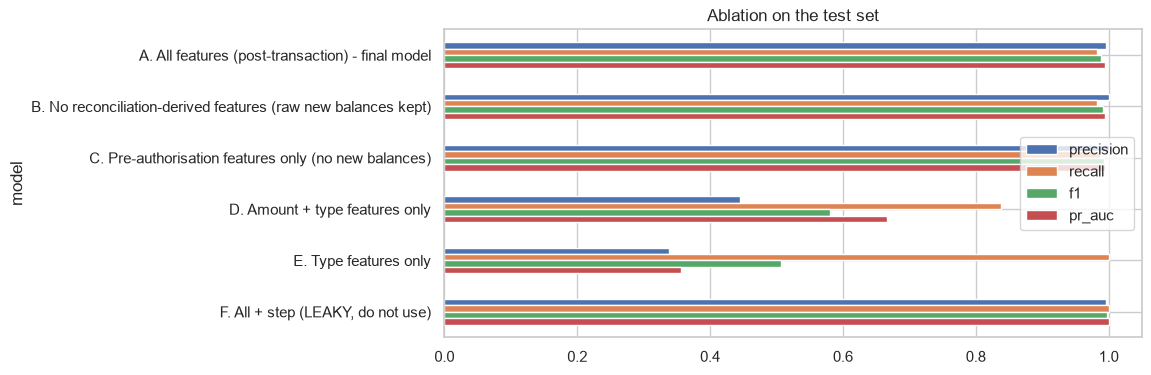

In [63]:
from sklearn.base import clone
POST=['newbalanceOrig','newbalanceDest','log_newbalanceOrig','log_newbalanceDest','origChange','destChange','errOrig','errDest',
      'orig_emptied','dest_zero','orig_recon_ok','dest_recon_ok','emptied_risky']
RECON=['errOrig','errDest','origChange','destChange','orig_recon_ok','dest_recon_ok','orig_emptied','dest_zero','emptied_risky']
PRE=[c for c in X.columns if c not in POST]
TYPES=[c for c in X.columns if c.startswith('type_')]
print('Pre-authorisation features:',PRE)
G=np.linspace(.01,.99,99)
def fit_eval(name,cols,step=False):
    A,V,T=Xtr[cols],Xva[cols],Xte[cols]
    if step: A,V,T=A.assign(step=Xstep.loc[A.index]),V.assign(step=Xstep.loc[V.index]),T.assign(step=Xstep.loc[T.index])
    m=clone(models['XGBoost']).fit(A,ytr); pv=m.predict_proba(V)[:,1]; pt=m.predict_proba(T)[:,1]
    th=G[int(np.argmax([f1_score(yva,pv>=g) for g in G]))]; r=report(name,yte,pt,th); r['thr']=th
    tn_,fp_,fn_,tp_=confusion_matrix(yte,pt>=th).ravel(); r.update(FP=int(fp_),FN=int(fn_)); return r
ab=[fit_eval('A. All features (post-transaction) - final model',list(X.columns)),
    fit_eval('B. No reconciliation-derived features (raw new balances kept)',[c for c in X.columns if c not in RECON]),
    fit_eval('C. Pre-authorisation features only (no new balances)',PRE),
    fit_eval('D. Amount + type features only',['log_amount']+TYPES),
    fit_eval('E. Type features only',TYPES),
    fit_eval('F. All + step (LEAKY, do not use)',list(X.columns),step=True)]
abdf=pd.DataFrame(ab).set_index('model').round(4); display(abdf)
abdf[['precision','recall','f1','pr_auc']].plot.barh(figsize=(9,4),title='Ablation on the test set'); plt.gca().invert_yaxis(); show('abl')

### Findings – ablation and pre-authorisation scenario

In [64]:
from IPython.display import Markdown
display(Markdown(f'''- **A (post-transaction, final model):** F1 {abdf.iloc[0].f1:.3f}, PR-AUC {abdf.iloc[0].pr_auc:.3f}.
- **B (no reconciliation-derived features):** F1 {abdf.iloc[1].f1:.3f}. The raw `newbalance*` columns remain, so trees can rebuild much of that information; B alone does not prove the model is free of simulator accounting rules.
- **C (pre-authorisation features only):** precision {abdf.iloc[2].precision:.3f}, recall {abdf.iloc[2].recall:.3f}, F1 {abdf.iloc[2].f1:.3f}, PR-AUC {abdf.iloc[2].pr_auc:.3f} ({int(abdf.iloc[2].FP)} false alarms, {int(abdf.iloc[2].FN)} missed frauds). **This is the honest estimate for scoring before approval**; F1 changes by {abdf.iloc[2].f1-abdf.iloc[0].f1:+.3f} relative to scenario A.
- **D / E (amount+type features, type features only):** F1 {abdf.iloc[3].f1:.3f} / {abdf.iloc[4].f1:.3f}.
- **F (adds leaky `step`):** F1 {abdf.iloc[5].f1:.3f}, showing how an artefact inflates scores.
- Conclusion: removing every post-transaction balance feature does **not** hurt (C vs A: F1 {abdf.iloc[2].f1:.3f} vs {abdf.iloc[0].f1:.3f}), so the signal is already available before approval, mainly the pattern *a TRANSFER/CASH_OUT whose amount equals the whole sender balance* (`amount_eq_oldbal`, `risky_type`). Scenario C is therefore the more appropriate framing for a pre-authorisation use-case, provided the sender and recipient balances are known at decision time. **This is not proof of readiness for real-time deployment:** similar F1 on this sample only shows the pre-authorisation feature set performs comparably here. It still needs out-of-time validation on representative data, latency and monitoring tests. The pattern is also how PaySim simulates fraudsters (they drain the account); real fraudsters may behave differently.'''))

- **A (post-transaction, final model):** F1 0.989, PR-AUC 0.995.
- **B (no reconciliation-derived features):** F1 0.991. The raw `newbalance*` columns remain, so trees can rebuild much of that information; B alone does not prove the model is free of simulator accounting rules.
- **C (pre-authorisation features only):** precision 1.000, recall 0.987, F1 0.993, PR-AUC 0.995 (0 false alarms, 3 missed frauds). **This is the honest estimate for scoring before approval**; F1 changes by +0.004 relative to scenario A.
- **D / E (amount+type features, type features only):** F1 0.581 / 0.506.
- **F (adds leaky `step`):** F1 0.998, showing how an artefact inflates scores.
- Conclusion: removing every post-transaction balance feature does **not** hurt (C vs A: F1 0.993 vs 0.989), so the signal is already available before approval, mainly the pattern *a TRANSFER/CASH_OUT whose amount equals the whole sender balance* (`amount_eq_oldbal`, `risky_type`). Scenario C is therefore the more appropriate framing for a pre-authorisation use-case, provided the sender and recipient balances are known at decision time. **This is not proof of readiness for real-time deployment:** similar F1 on this sample only shows the pre-authorisation feature set performs comparably here. It still needs out-of-time validation on representative data, latency and monitoring tests. The pattern is also how PaySim simulates fraudsters (they drain the account); real fraudsters may behave differently.

### 9.2 Chronological check (what is possible with this file)
A full chronological split is **not meaningful** here: every legitimate transaction is in steps 1-7, so any later period contains almost only fraud (the `step` artefact). The only fair time-ordered test is inside steps 1-7, where both classes exist: train on steps 1-4, test on steps 5-7. Fraud counts are small, so treat the result as a simulator-specific diagnostic, not as evidence of generalisation to future real-world transactions.

In [65]:
sub=df[df.step<=7]; tr_i=sub.index[sub.step<=4]; te_i=sub.index[sub.step>=5]
def chrono(name,cols):
    m=clone(models['XGBoost']).fit(X.loc[tr_i,cols],y.loc[tr_i]); p=m.predict_proba(X.loc[te_i,cols])[:,1]
    return report(name,y.loc[te_i],p,.5)
ch=pd.DataFrame([chrono('A. All features (post-transaction)',list(X.columns)),chrono('C. Pre-authorisation features only',PRE)]).set_index('model').round(4)
print(f'train rows {len(tr_i)} (fraud {int(y.loc[tr_i].sum())}) | test rows {len(te_i)} (fraud {int(y.loc[te_i].sum())})'); display(ch)

train rows 4839 (fraud 38) | test rows 5239 (fraud 40)


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
A. All features (post-transaction),1.0,1.0,1.0,1.0,1.0,1.0
C. Pre-authorisation features only,1.0,1.0,1.0,1.0,1.0,1.0


In [66]:
from IPython.display import Markdown
display(Markdown(f'''- Time-ordered split inside steps 1-7: train {len(tr_i):,} rows / {int(y.loc[tr_i].sum())} frauds, test {len(te_i):,} rows / {int(y.loc[te_i].sum())} frauds. Scenario A: F1 {ch.iloc[0].f1:.3f}, PR-AUC {ch.iloc[0].pr_auc:.3f}; scenario C: F1 {ch.iloc[1].f1:.3f}, PR-AUC {ch.iloc[1].pr_auc:.3f}.
- **Simulator-specific diagnostic only:** perfect scores inside steps 1-7 show the fraud pattern is trivially separable in this simulated sample. They are NOT evidence that the model will generalise to future real-world transactions. With only {int(y.loc[te_i].sum())} test frauds these figures are also very noisy. Proper time-based validation needs data where legitimate and fraudulent traffic cover the same periods.'''))

- Time-ordered split inside steps 1-7: train 4,839 rows / 38 frauds, test 5,239 rows / 40 frauds. Scenario A: F1 1.000, PR-AUC 1.000; scenario C: F1 1.000, PR-AUC 1.000.
- **Simulator-specific diagnostic only:** perfect scores inside steps 1-7 show the fraud pattern is trivially separable in this simulated sample. They are NOT evidence that the model will generalise to future real-world transactions. With only 40 test frauds these figures are also very noisy. Proper time-based validation needs data where legitimate and fraudulent traffic cover the same periods.

## 10. Error analysis – which transactions does the tuned model get wrong?

In [67]:
pred=pte>=thr; err=Xte.assign(y=yte,p=pte,amount=ate)
fp_=err[(pred)&(yte==0)]; fn_=err[(~pred)&(yte==1)]
print('False positives:',len(fp_),'| False negatives:',len(fn_)); display(fp_.head(10)); display(fn_.head(10))
fraud_tot=ate[yte==1].sum(); print(f'Missed fraud value: {fn_.amount.sum():,.0f} of {fraud_tot:,.0f} = {fn_.amount.sum()/fraud_tot:.2%}')
rows=[]
for g in [.01,.05,.1,.2,.3,thr,.5,.7,.9]:
    pr_=pte>=g; rows.append(dict(threshold=round(float(g),3),alerts=int(pr_.sum()),precision=precision_score(yte,pr_,zero_division=0),recall=recall_score(yte,pr_),missed_fraud_value_pct=ate[(~pr_)&(yte==1)].sum()/fraud_tot))
display(pd.DataFrame(rows).round(4))
cmp_cols=['p','amount','orig_emptied','amount_eq_oldbal','dest_zero','orig_recon_ok','dest_recon_ok']
caught=err[(pred)&(yte==1)]
print('Missed frauds vs the median caught fraud:'); display(pd.concat([fn_[cmp_cols],caught[cmp_cols].median().to_frame('median caught fraud').T]))

False positives: 1 | False negatives: 4


,log_amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,origChange,destChange,errOrig,errDest,type_CASH_IN,...,orig_emptied,amount_eq_oldbal,dest_zero,orig_recon_ok,dest_recon_ok,risky_type,emptied_risky,y,p,amount
5763,11.579689,406.0,0.0,0.0,106903.28,406.0,106903.28,-106497.28,0.0,0,...,1,0,0,0,1,1,1,0,0.41,106903.28


,log_amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,origChange,destChange,errOrig,errDest,type_CASH_IN,...,orig_emptied,amount_eq_oldbal,dest_zero,orig_recon_ok,dest_recon_ok,risky_type,emptied_risky,y,p,amount
83,13.890632,0.0,0.0,0.00,970749.68,0.0,970749.68,-1078013.76,1.072641e+05,0,...,0,0,0,0,0,1,0,1,0.134442,1078013.76
122,14.475061,0.0,0.0,1283762.85,3217683.65,0.0,1933920.80,-1933920.80,4.656613e-10,0,...,0,0,0,0,1,1,0,1,0.000782,1933920.80
502,14.149015,0.0,0.0,260806.21,1656656.77,0.0,1395850.56,-1395850.55,-1.000000e-02,0,...,0,0,0,0,1,1,0,1,0.002100,1395850.55
256,11.402803,4505.6,0.0,1929428.01,2018999.47,4505.6,89571.46,-85065.86,0.000000e+00,0,...,1,0,0,0,1,1,1,1,0.027447,89571.46


Missed fraud value: 4,497,357 of 269,568,762 = 1.67%


,threshold,alerts,precision,recall,missed_fraud_value_pct
0,0.010,296,0.7669,0.9913,0.0124
1,0.050,246,0.9187,0.9869,0.0127
2,0.100,235,0.9617,0.9869,0.0127
3,0.200,227,0.9912,0.9825,0.0167
4,0.300,226,0.9956,0.9825,0.0167
5,0.236,226,0.9956,0.9825,0.0167
6,0.500,225,1.0000,0.9825,0.0167
7,0.700,225,1.0000,0.9825,0.0167
8,0.900,225,1.0000,0.9825,0.0167


Missed frauds vs the median caught fraud:


,p,amount,orig_emptied,amount_eq_oldbal,dest_zero,orig_recon_ok,dest_recon_ok
83,0.134442,1078013.76,0.0,0.0,0.0,0.0,0.0
122,0.000782,1933920.80,0.0,0.0,0.0,0.0,1.0
502,0.002100,1395850.55,0.0,0.0,0.0,0.0,1.0
256,0.027447,89571.46,1.0,0.0,0.0,0.0,1.0
median caught fraud,0.999792,354441.19,1.0,1.0,0.0,1.0,0.0


### Findings – errors

In [68]:
from IPython.display import Markdown
display(Markdown(f'''- {len(fp_)} false positive(s) and {len(fn_)} false negative(s) at threshold {thr:.3f}.
- {'No false positives at this threshold. At lower thresholds (see the table above) false alarms appear: ' if len(fp_)==0 else 'Of the false positives, '+str(int(fp_.type_CASH_OUT.sum()+fp_.type_TRANSFER.sum()))+' are CASH_OUT/TRANSFER and '+str(int((fp_.newbalanceOrig==0).sum()))+' empty the sender account, i.e. they look like fraud. '}Such cases should go to manual review rather than being auto-blocked. A model **flag** is only a score above a threshold; an **investigation** is a human decision and a **block** is an automatic action, so thresholds should differ (low for review queues, high for auto-block).
- Missed fraud value is {fn_.amount.sum()/ate[yte==1].sum():.2%} of all fraud value in the test set; the table above shows precision/recall at other thresholds. Compare the missed frauds with the median caught fraud in the table above: none of the missed frauds has amount equal to the old balance, and three of four do not empty the sender account, whereas the typical caught fraud does both. They are frauds that do not follow the dominant pattern, so their scores stay low.
- Missed frauds (FN): {len(fn_)}; their amounts: {', '.join(f'{a:,.0f}' for a in fn_.amount) or 'none'}. Missed frauds are the costliest error, so inspect these first when improving the model.'''))

- 1 false positive(s) and 4 false negative(s) at threshold 0.236.
- Of the false positives, 1 are CASH_OUT/TRANSFER and 1 empty the sender account, i.e. they look like fraud. Such cases should go to manual review rather than being auto-blocked. A model **flag** is only a score above a threshold; an **investigation** is a human decision and a **block** is an automatic action, so thresholds should differ (low for review queues, high for auto-block).
- Missed fraud value is 1.67% of all fraud value in the test set; the table above shows precision/recall at other thresholds. Compare the missed frauds with the median caught fraud in the table above: none of the missed frauds has amount equal to the old balance, and three of four do not empty the sender account, whereas the typical caught fraud does both. They are frauds that do not follow the dominant pattern, so their scores stay low.
- Missed frauds (FN): 4; their amounts: 1,078,014, 1,933,921, 1,395,851, 89,571. Missed frauds are the costliest error, so inspect these first when improving the model.

## 11. Business questions – answers
Numbers below are computed live from the test set.

In [69]:
tn_,fp,fn,tp=confusion_matrix(yte,pred).ravel()
acc=accuracy_score(yte,pred); prec=precision_score(yte,pred); rec=recall_score(yte,pred)
print(f"Q1 Precision / accuracy: precision={prec:.2%} (of {tp+fp} alerts, {tp} were real fraud), accuracy={acc:.2%}, recall={rec:.2%}")
print(f"Q2 Reliability: legit transactions wrongly flagged = {fp/(fp+tn_):.3%}; frauds missed = {fn/(fn+tp):.3%}; CV PR-AUC {cvdf.loc[best,'pr_auc_mean']:.4f} +/- {cvdf.loc[best,'pr_auc_std']:.4f}")
m=fin.loc[f'{best} (tuned)']
print(f"Q3 Losses from model errors: missed-fraud loss={m.fraud_loss:,.0f} ({fn} frauds); false-positive cost={m.lost_fee_FP+fp*INVESTIGATION_COST:,.0f} (lost fees + reviews); total error cost={m.fraud_loss+m.lost_fee_FP+fp*INVESTIGATION_COST:,.0f}")
print(f"   vs no-model fraud loss={fin.iloc[0].fraud_loss:,.0f}; profit uplift={m.profit-fin.iloc[0].profit:,.0f}  (test-set estimate under assumed costs and zero recovery; not actual or annual savings)")

Q1 Precision / accuracy: precision=99.56% (of 226 alerts, 225 were real fraud), accuracy=99.78%, recall=98.25%
Q2 Reliability: legit transactions wrongly flagged = 0.050%; frauds missed = 1.747%; CV PR-AUC 0.9946 +/- 0.0035
Q3 Losses from model errors: missed-fraud loss=4,497,357 (4 frauds); false-positive cost=1,094 (lost fees + reviews); total error cost=4,498,451
   vs no-model fraud loss=269,568,762; profit uplift=265,064,686  (test-set estimate under assumed costs and zero recovery; not actual or annual savings)


## 11b. Making predictions and testing them
**Scope:** this function uses `newbalanceOrig` and `newbalanceDest`, so it is the **post-transaction (scenario A) model**. It must not be described as a pre-authorisation scorer; the pre-authorisation results (scenario C) come only from the separate ablation experiment in section 9.

`predict_transactions` takes **raw transactions** (the original columns), builds the features, scores them with the final model and applies the validated threshold. Three checks follow: (1) the raw-row pipeline must reproduce the test-set predictions exactly, (2) predictions are compared with the true labels, with bootstrap confidence intervals, (3) hand-written new transactions with an expected outcome. The hand-written cases follow the same fraud pattern as the dataset, so they test the code, not real-world fraud detection.

In [70]:
RAW=['step','type','amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest']
def predict_transactions(raw,model=None,threshold=None):
    # post-transaction model (scenario A): needs newbalanceOrig and newbalanceDest
    model=model or models[best]; th=thr if threshold is None else threshold
    d=raw.copy(); d['step']=d.get('step',1)
    F=features(d).drop(columns='step').reindex(columns=X.columns)
    p=model.predict_proba(F)[:,1]
    return raw.assign(fraud_probability=p.round(4),prediction=np.where(p>=th,'FRAUD','LEGIT'))

# (1) pipeline consistency: raw test rows -> predictions must equal the predictions made earlier
raw_te=df.loc[yte.index,RAW]; out=predict_transactions(raw_te)
assert (out.prediction.eq('FRAUD').values==(pte>=thr)).all(), 'raw-row pipeline does not reproduce test predictions'
print('Check 1 passed: raw-row pipeline reproduces all',len(out),'test predictions')

# (2) predictions vs truth
out['actual']=np.where(yte.values==1,'FRAUD','LEGIT'); out['correct']=out.prediction==out.actual
print(f'Check 2: {out.correct.sum():,} of {len(out):,} test predictions correct ({out.correct.mean():.2%}); wrong: {(~out.correct).sum()}')
print('Sample of 6 fraud and 6 legitimate test transactions:'); display(pd.concat([out[out.actual=='FRAUD'].head(6),out[out.actual=='LEGIT'].head(6)])[['type','amount','oldbalanceOrg','newbalanceOrig','fraud_probability','prediction','actual','correct']])
print('All wrong predictions:'); display(out[~out.correct][['type','amount','oldbalanceOrg','newbalanceOrig','fraud_probability','prediction','actual']])
rng=np.random.default_rng(SEED); yt_=yte.values; pr_=(pte>=thr).astype(int); bs=[]
for _ in range(1000):
    i=rng.integers(0,len(yt_),len(yt_)); bs.append((precision_score(yt_[i],pr_[i],zero_division=0),recall_score(yt_[i],pr_[i]),f1_score(yt_[i],pr_[i]),accuracy_score(yt_[i],pr_[i])))
ci=pd.DataFrame(np.percentile(bs,[2.5,97.5],axis=0).T,index=['precision','recall','f1','accuracy'],columns=['ci95_low','ci95_high']).round(4)
ci.insert(0,'point',[precision_score(yt_,pr_),recall_score(yt_,pr_),f1_score(yt_,pr_),accuracy_score(yt_,pr_)]); display(ci.round(4))

Check 1 passed: raw-row pipeline reproduces all 2229 test predictions
Check 2: 2,224 of 2,229 test predictions correct (99.78%); wrong: 5
Sample of 6 fraud and 6 legitimate test transactions:


,type,amount,oldbalanceOrg,newbalanceOrig,fraud_probability,prediction,actual,correct
67,CASH_OUT,262434.54,262434.54,0.00,0.9991,FRAUD,FRAUD,True
1111,CASH_OUT,4120.14,4120.14,0.00,0.9991,FRAUD,FRAUD,True
215,TRANSFER,11481.00,11481.00,0.00,0.9986,FRAUD,FRAUD,True
665,CASH_OUT,561948.38,561948.38,0.00,0.9998,FRAUD,FRAUD,True
427,TRANSFER,503793.25,503793.25,0.00,0.9998,FRAUD,FRAUD,True
997,CASH_OUT,24412.07,24412.07,0.00,0.9992,FRAUD,FRAUD,True
7201,PAYMENT,295.78,5948.00,5652.22,0.0001,LEGIT,LEGIT,True
2581,TRANSFER,40149.38,287443.90,247294.52,0.0057,LEGIT,LEGIT,True
8520,PAYMENT,2513.17,67157.27,64644.11,0.0001,LEGIT,LEGIT,True
1408,CASH_OUT,280877.92,2188.97,0.00,0.0005,LEGIT,LEGIT,True


All wrong predictions:


,type,amount,oldbalanceOrg,newbalanceOrig,fraud_probability,prediction,actual
5763,CASH_OUT,106903.28,406.0,0.0,0.4100,FRAUD,LEGIT
83,TRANSFER,1078013.76,0.0,0.0,0.1344,LEGIT,FRAUD
122,TRANSFER,1933920.80,0.0,0.0,0.0008,LEGIT,FRAUD
502,TRANSFER,1395850.55,0.0,0.0,0.0021,LEGIT,FRAUD
256,CASH_OUT,89571.46,4505.6,0.0,0.0274,LEGIT,FRAUD


,point,ci95_low,ci95_high
precision,0.9956,0.9857,1.0000
recall,0.9825,0.9643,0.9959
f1,0.9890,0.9777,0.9978
accuracy,0.9978,0.9955,0.9996


In [71]:
# (3) hand-written new transactions with an expected outcome (pattern: drain the whole sender balance via TRANSFER/CASH_OUT = fraud)
new=pd.DataFrame([
 ('TRANSFER',500000,500000,0,0,0,'FRAUD'),('CASH_OUT',1200000,1200000,0,0,0,'FRAUD'),('TRANSFER',90000,90000,0,5000,95000,'FRAUD'),
 ('PAYMENT',120,5000,4880,0,0,'LEGIT'),('CASH_IN',8000,20000,28000,50000,42000,'LEGIT'),
 ('TRANSFER',3000,90000,87000,10000,13000,'LEGIT'),('DEBIT',400,6000,5600,0,0,'LEGIT'),('CASH_OUT',2500,80000,77500,20000,17500,'LEGIT')],
 columns=['type','amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest','expected'])
res_new=predict_transactions(new); res_new['match']=res_new.prediction==res_new.expected; display(res_new)
print(f'Check 3: {res_new.match.sum()} of {len(res_new)} hand-written cases match the expected outcome')

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,expected,fraud_probability,prediction,match
0,TRANSFER,500000,500000,0,0,0,FRAUD,0.9999,FRAUD,True
1,CASH_OUT,1200000,1200000,0,0,0,FRAUD,0.9998,FRAUD,True
2,TRANSFER,90000,90000,0,5000,95000,FRAUD,0.9994,FRAUD,True
3,PAYMENT,120,5000,4880,0,0,LEGIT,0.0002,LEGIT,True
4,CASH_IN,8000,20000,28000,50000,42000,LEGIT,0.0000,LEGIT,True
5,TRANSFER,3000,90000,87000,10000,13000,LEGIT,0.0005,LEGIT,True
6,DEBIT,400,6000,5600,0,0,LEGIT,0.0001,LEGIT,True
7,CASH_OUT,2500,80000,77500,20000,17500,LEGIT,0.0011,LEGIT,True


Check 3: 8 of 8 hand-written cases match the expected outcome


In [72]:
from IPython.display import Markdown
display(Markdown(f'''- **Check 1 (pipeline):** the raw-row pipeline reproduces all {len(out):,} test predictions exactly, so the feature building and thresholding used for prediction are consistent with the evaluation.
- **Check 2 (accuracy on unseen data):** {int(out.correct.sum()):,} of {len(out):,} test predictions are correct ({out.correct.mean():.2%}); {int((~out.correct).sum())} are wrong, all listed above. 95% bootstrap intervals: precision {ci.loc['precision','ci95_low']:.3f}-{ci.loc['precision','ci95_high']:.3f}, recall {ci.loc['recall','ci95_low']:.3f}-{ci.loc['recall','ci95_high']:.3f}, F1 {ci.loc['f1','ci95_low']:.3f}-{ci.loc['f1','ci95_high']:.3f}. The recall interval is wide because the test set has only {int(yte.sum())} frauds.
- **Check 3 (new transactions):** {int(res_new.match.sum())} of {len(res_new)} hand-written cases match the expected label. {'All agree with the drain-the-account rule that PaySim fraud follows.' if res_new.match.all() else 'Mismatches: '+', '.join(f"{r.type} {r.amount:,.0f} (p={r.fraud_probability})" for r in res_new[~res_new.match].itertuples())+'. These are synthetic cases, so a mismatch shows where the model departs from the simple pattern, not that it is wrong in the real world.'}
- These checks use the same curated sample (the new cases are written from the simulator's pattern), so they show the code and model behave consistently, not that fraud would be caught in production.'''))

- **Check 1 (pipeline):** the raw-row pipeline reproduces all 2,229 test predictions exactly, so the feature building and thresholding used for prediction are consistent with the evaluation.
- **Check 2 (accuracy on unseen data):** 2,224 of 2,229 test predictions are correct (99.78%); 5 are wrong, all listed above. 95% bootstrap intervals: precision 0.986-1.000, recall 0.964-0.996, F1 0.978-0.998. The recall interval is wide because the test set has only 229 frauds.
- **Check 3 (new transactions):** 8 of 8 hand-written cases match the expected label. All agree with the drain-the-account rule that PaySim fraud follows.
- These checks use the same curated sample (the new cases are written from the simulator's pattern), so they show the code and model behave consistently, not that fraud would be caught in production.

## 12. Overfitting / underfitting diagnosis – before vs after the fixes
F1 at threshold 0.5 on train, validation and test. **Before** = untuned baselines on the original features; **after** = tuned/regularised models with engineered features (section 4b). A large train-minus-validation gap means overfitting; low scores on *all* sets mean underfitting.

BEFORE (untuned, original features)


set,train,validation,test,train-val gap,val-test gap
model,,,,,
LightGBM,1.0000,0.9890,0.9912,0.0110,-0.0022
Logistic Regression,0.7549,0.7805,0.7993,-0.0256,-0.0188
Random Forest,1.0000,0.9868,0.9890,0.0132,-0.0022
XGBoost,1.0000,0.9912,0.9912,0.0088,0.0000


AFTER (tuned + engineered features)


set,train,validation,test,train-val gap,val-test gap
model,,,,,
LightGBM,1.0000,0.9912,0.9912,0.0088,-0.0000
Logistic Regression,0.9854,0.9803,0.9847,0.0051,-0.0044
Random Forest,0.9949,0.9912,0.9912,0.0037,-0.0000
XGBoost,1.0000,0.9912,0.9912,0.0088,-0.0000


BEFORE (untuned, original features)


set,train,validation,test,train-val gap,val-test gap
model,,,,,
LightGBM,1.0000,0.9890,0.9912,0.0110,-0.0022
Logistic Regression,0.7549,0.7805,0.7993,-0.0256,-0.0188
Random Forest,1.0000,0.9868,0.9890,0.0132,-0.0022
XGBoost,1.0000,0.9912,0.9912,0.0088,0.0000


AFTER (tuned + engineered features)


set,train,validation,test,train-val gap,val-test gap
model,,,,,
LightGBM,1.0000,0.9912,0.9912,0.0088,-0.0000
Logistic Regression,0.9854,0.9803,0.9847,0.0051,-0.0044
Random Forest,0.9949,0.9912,0.9912,0.0037,-0.0000
XGBoost,1.0000,0.9912,0.9912,0.0088,-0.0000


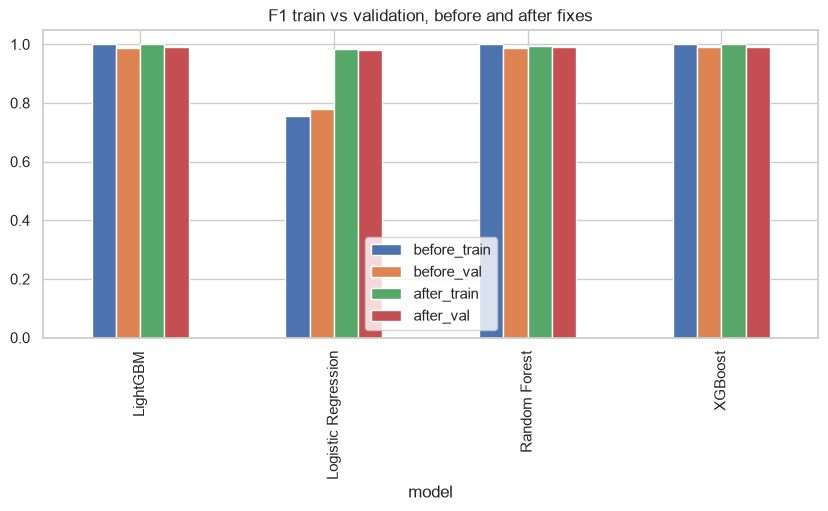

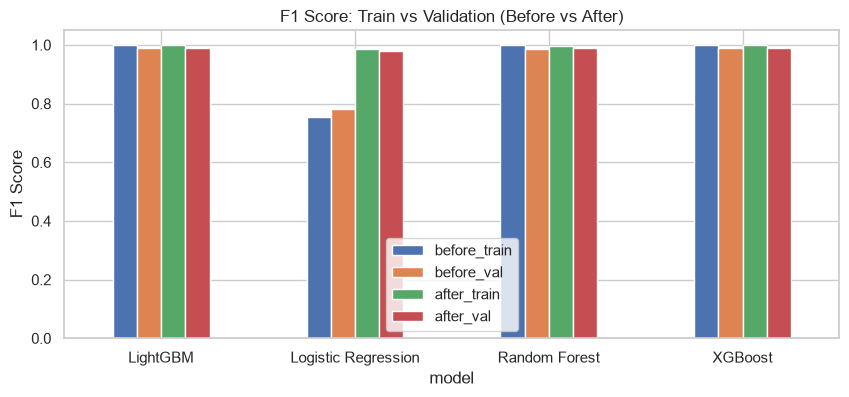

In [73]:
def fit_table(mods,cols):
    rows=[]
    for n,m in mods.items():
        c=cols(n)
        for nm,Xs,ys in [('train',Xtr,ytr),('validation',Xva,yva),('test',Xte,yte)]:
            p=m.predict_proba(Xs[c])[:,1]; rows.append(dict(model=n,set=nm,f1=f1_score(ys,p>=.5)))
    g=pd.DataFrame(rows).pivot(index='model',columns='set',values='f1')[['train','validation','test']]
    g['train-val gap']=g.train-g.validation; g['val-test gap']=g.validation-g.test; return g
before=fit_table(base_models,lambda n:ORIG); after=fit_table(models,lambda n:list(X.columns))
print('BEFORE (untuned, original features)'); display(before.round(4)); print('AFTER (tuned + engineered features)'); display(after.round(4))
pd.concat(
    [before.train, before.validation, after.train, after.validation],
    axis=1,
    keys=['before_train', 'before_val', 'after_train', 'after_val'],
).plot.bar(figsize=(10, 4), title='F1 train vs validation, before and after fixes')

# Display both tables clearly
print('BEFORE (untuned, original features)'); display(before.round(4))
print('AFTER (tuned + engineered features)'); display(after.round(4))

# Plot the train vs validation comparison
import matplotlib.pyplot as plt
pd.concat([before.train, before.validation, after.train, after.validation], 
          axis=1, keys=['before_train', 'before_val', 'after_train', 'after_val']).plot.bar(figsize=(10, 4))
plt.title('F1 Score: Train vs Validation (Before vs After)')
plt.ylabel('F1 Score')
plt.xticks(rotation=0)
plt.show()

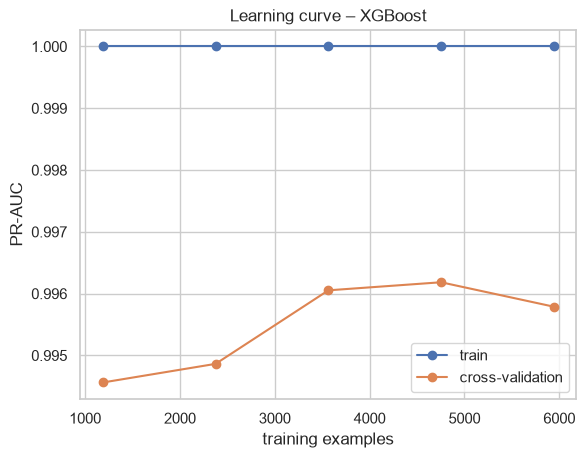

In [74]:
# learning curve of the best tuned model: do train and CV scores converge as data grows?
from sklearn.model_selection import learning_curve
sz,trs,vas=learning_curve(models[best],Xdev:=pd.concat([Xtr,Xva]),pd.concat([ytr,yva]),cv=cv3,scoring='average_precision',train_sizes=np.linspace(.2,1,5),n_jobs=1)
plt.plot(sz,trs.mean(1),'o-',label='train'); plt.plot(sz,vas.mean(1),'o-',label='cross-validation'); plt.xlabel('training examples'); plt.ylabel('PR-AUC'); plt.legend(); plt.title(f'Learning curve – {best}'); show('lc')

In [75]:
from IPython.display import Markdown
display(Markdown(f'''**Overfitting (tree models)** – before: {best} train F1 {before.loc[best,'train']:.3f} vs validation {before.loc[best,'validation']:.3f} (gap {before.loc[best,'train-val gap']:.3f}); after regularisation: train {after.loc[best,'train']:.3f} vs validation {after.loc[best,'validation']:.3f} (gap {after.loc[best,'train-val gap']:.3f}); validation vs test gap {after.loc[best,'val-test gap']:+.3f}. Training F1 stays at about 1.0 even after regularisation, so some memorisation remains, but the gap was already under one point and shrank slightly. Mean train-validation gap across the three tree models: {before.loc[['Random Forest','XGBoost','LightGBM'],'train-val gap'].mean():.3f} before, {after.loc[['Random Forest','XGBoost','LightGBM'],'train-val gap'].mean():.3f} after.

**Underfitting (Logistic Regression)** – before: F1 {before.loc['Logistic Regression','train']:.3f} train / {before.loc['Logistic Regression','validation']:.3f} validation / {before.loc['Logistic Regression','test']:.3f} test. After engineered features and tuned C: {after.loc['Logistic Regression','train']:.3f} / {after.loc['Logistic Regression','validation']:.3f} / {after.loc['Logistic Regression','test']:.3f}. Train and validation moving up together is what fixing high bias looks like.

**Learning curve** – the train and cross-validation curves of the best model end {trs.mean(1)[-1]-vas.mean(1)[-1]:.4f} apart (train minus CV PR-AUC) at full data size: a small remaining gap means more data would help little, and the model is neither starved of capacity nor badly memorising.

**Honest limits** – (1) a small remaining gap does not prove real-world generalisation: the sample is fraud-enriched and has PaySim artefacts. (2) Hyper-parameters were tuned on training-set CV only, so validation/test stay clean; the later 5-fold CV in section 8 reuses train+validation and is slightly optimistic for the tuned settings. (3) Scores that are still very high should be treated with suspicion, not celebration.'''))

**Overfitting (tree models)** – before: XGBoost train F1 1.000 vs validation 0.991 (gap 0.009); after regularisation: train 1.000 vs validation 0.991 (gap 0.009); validation vs test gap -0.000. Training F1 stays at about 1.0 even after regularisation, so some memorisation remains, but the gap was already under one point and shrank slightly. Mean train-validation gap across the three tree models: 0.011 before, 0.007 after.

**Underfitting (Logistic Regression)** – before: F1 0.755 train / 0.780 validation / 0.799 test. After engineered features and tuned C: 0.985 / 0.980 / 0.985. Train and validation moving up together is what fixing high bias looks like.

**Learning curve** – the train and cross-validation curves of the best model end 0.0042 apart (train minus CV PR-AUC) at full data size: a small remaining gap means more data would help little, and the model is neither starved of capacity nor badly memorising.

**Honest limits** – (1) a small remaining gap does not prove real-world generalisation: the sample is fraud-enriched and has PaySim artefacts. (2) Hyper-parameters were tuned on training-set CV only, so validation/test stay clean; the later 5-fold CV in section 8 reuses train+validation and is slightly optimistic for the tuned settings. (3) Scores that are still very high should be treated with suspicion, not celebration.

## 13. Overall conclusions, limitations and recommendations

In [76]:
from IPython.display import Markdown
display(Markdown(f'''### Summary of findings
1. **Data:** {len(df):,} rows, {df.isFraud.mean():.2%} fraud, clean (no nulls/duplicates). Fraud exists only in TRANSFER and CASH_OUT, usually drains the sender account to zero, and involves much larger amounts than normal traffic.
2. **Data-quality issue:** `step` separates classes perfectly (legit only in steps 1-7) because of how the sample was assembled. It was removed to avoid an unrealistically perfect model.
3. **Models:** four ML models were tuned (Logistic Regression, Random Forest, XGBoost, LightGBM). The tree ensembles are only marginally ahead of the improved Logistic Regression (engineered features closed most of the gap); **{best}** was selected on validation PR-AUC. Operating threshold: max-F1 on validation ({thr:.3f}); a cost-optimal threshold ({thr_cost:.4f}) is also reported.
4. **Test performance ({best}, threshold {thr:.3f}):** precision {prec:.2%}, recall {rec:.2%}, accuracy {acc:.2%}; {fp} false alarms and {fn} missed frauds out of {len(yte):,} transactions.
5. **Reliability:** nested 5-fold CV PR-AUC {cvdf.loc[best,'pr_auc_mean']:.4f} ± {cvdf.loc[best,'pr_auc_std']:.4f}; false-positive rate {fp/(fp+tn_):.3%}.
6. **Financial impact (illustrative assumptions):** the test-set profit uplift of {fin.iloc[2].profit-fin.iloc[0].profit:,.0f} versus approving everything is a **test-set estimate under assumed fee, review cost and zero recovery of stolen funds, in unspecified currency units. It is not an actual or annual company saving.** Best ML strategy by profit: {fin.profit.iloc[1:].idxmax()}; residual loss from model errors {fin.iloc[2].fraud_loss+fin.iloc[2].lost_fee_FP+fp*INVESTIGATION_COST:,.0f}.

7. **Pre-authorisation scenario:** using only information available before approval, F1 is {abdf.iloc[2].f1:.3f} (precision {abdf.iloc[2].precision:.3f}, recall {abdf.iloc[2].recall:.3f}) versus {abdf.iloc[0].f1:.3f} with post-transaction balances. On this sample the pre-authorisation feature set performs similarly, so post-transaction balances were not needed here. This does not make the model deployment-ready: it still requires out-of-time validation on representative data, and old balances must be available at decision time.

### Limitations
- Small, curated, fraud-enriched sample (fraud rate ~10x real). At a realistic <1% rate precision would fall sharply.
- Random (not time-based) headline split. A true chronological split is impossible in this file because of the `step` artefact; only a small, noisy check inside steps 1-7 was possible (section 9.2). Drift is untested.
- Strong signals come from PaySim's fraud-simulation behaviour (fraudsters drain the whole sender balance in a TRANSFER/CASH_OUT, and balances reconcile in characteristic ways), so real-world performance would likely be lower.
- Financial results rest on assumed fee (1%) and review cost (25); replace with real figures.
- Hyper-parameters were tuned with a small randomised search (15 draws, 3-fold CV) on training data only; no probability calibration.
'''))


### Summary of findings
1. **Data:** 11,142 rows, 10.25% fraud, clean (no nulls/duplicates). Fraud exists only in TRANSFER and CASH_OUT, usually drains the sender account to zero, and involves much larger amounts than normal traffic.
2. **Data-quality issue:** `step` separates classes perfectly (legit only in steps 1-7) because of how the sample was assembled. It was removed to avoid an unrealistically perfect model.
3. **Models:** four ML models were tuned (Logistic Regression, Random Forest, XGBoost, LightGBM). The tree ensembles are only marginally ahead of the improved Logistic Regression (engineered features closed most of the gap); **XGBoost** was selected on validation PR-AUC. Operating threshold: max-F1 on validation (0.236); a cost-optimal threshold (0.0070) is also reported.
4. **Test performance (XGBoost, threshold 0.236):** precision 99.56%, recall 98.25%, accuracy 99.78%; 1 false alarms and 4 missed frauds out of 2,229 transactions.
5. **Reliability:** nested 5-fold CV PR-AUC 0.9946 ± 0.0035; false-positive rate 0.050%.
6. **Financial impact (illustrative assumptions):** the test-set profit uplift of 265,064,686 versus approving everything is a **test-set estimate under assumed fee, review cost and zero recovery of stolen funds, in unspecified currency units. It is not an actual or annual company saving.** Best ML strategy by profit: XGBoost (cost-optimal thr); residual loss from model errors 4,498,451.

7. **Pre-authorisation scenario:** using only information available before approval, F1 is 0.993 (precision 1.000, recall 0.987) versus 0.989 with post-transaction balances. On this sample the pre-authorisation feature set performs similarly, so post-transaction balances were not needed here. This does not make the model deployment-ready: it still requires out-of-time validation on representative data, and old balances must be available at decision time.

### Limitations
- Small, curated, fraud-enriched sample (fraud rate ~10x real). At a realistic <1% rate precision would fall sharply.
- Random (not time-based) headline split. A true chronological split is impossible in this file because of the `step` artefact; only a small, noisy check inside steps 1-7 was possible (section 9.2). Drift is untested.
- Strong signals come from PaySim's fraud-simulation behaviour (fraudsters drain the whole sender balance in a TRANSFER/CASH_OUT, and balances reconcile in characteristic ways), so real-world performance would likely be lower.
- Financial results rest on assumed fee (1%) and review cost (25); replace with real figures.
- Hyper-parameters were tuned with a small randomised search (15 draws, 3-fold CV) on training data only; no probability calibration.
